Loading …
Done.
Column headers: ['$d_{\\max} = 0.20$', '$d_{\\max} \\approx 0.60$', '$d_{\\max} \\approx 0.90$', '$d_{\\max} = 1.00$']


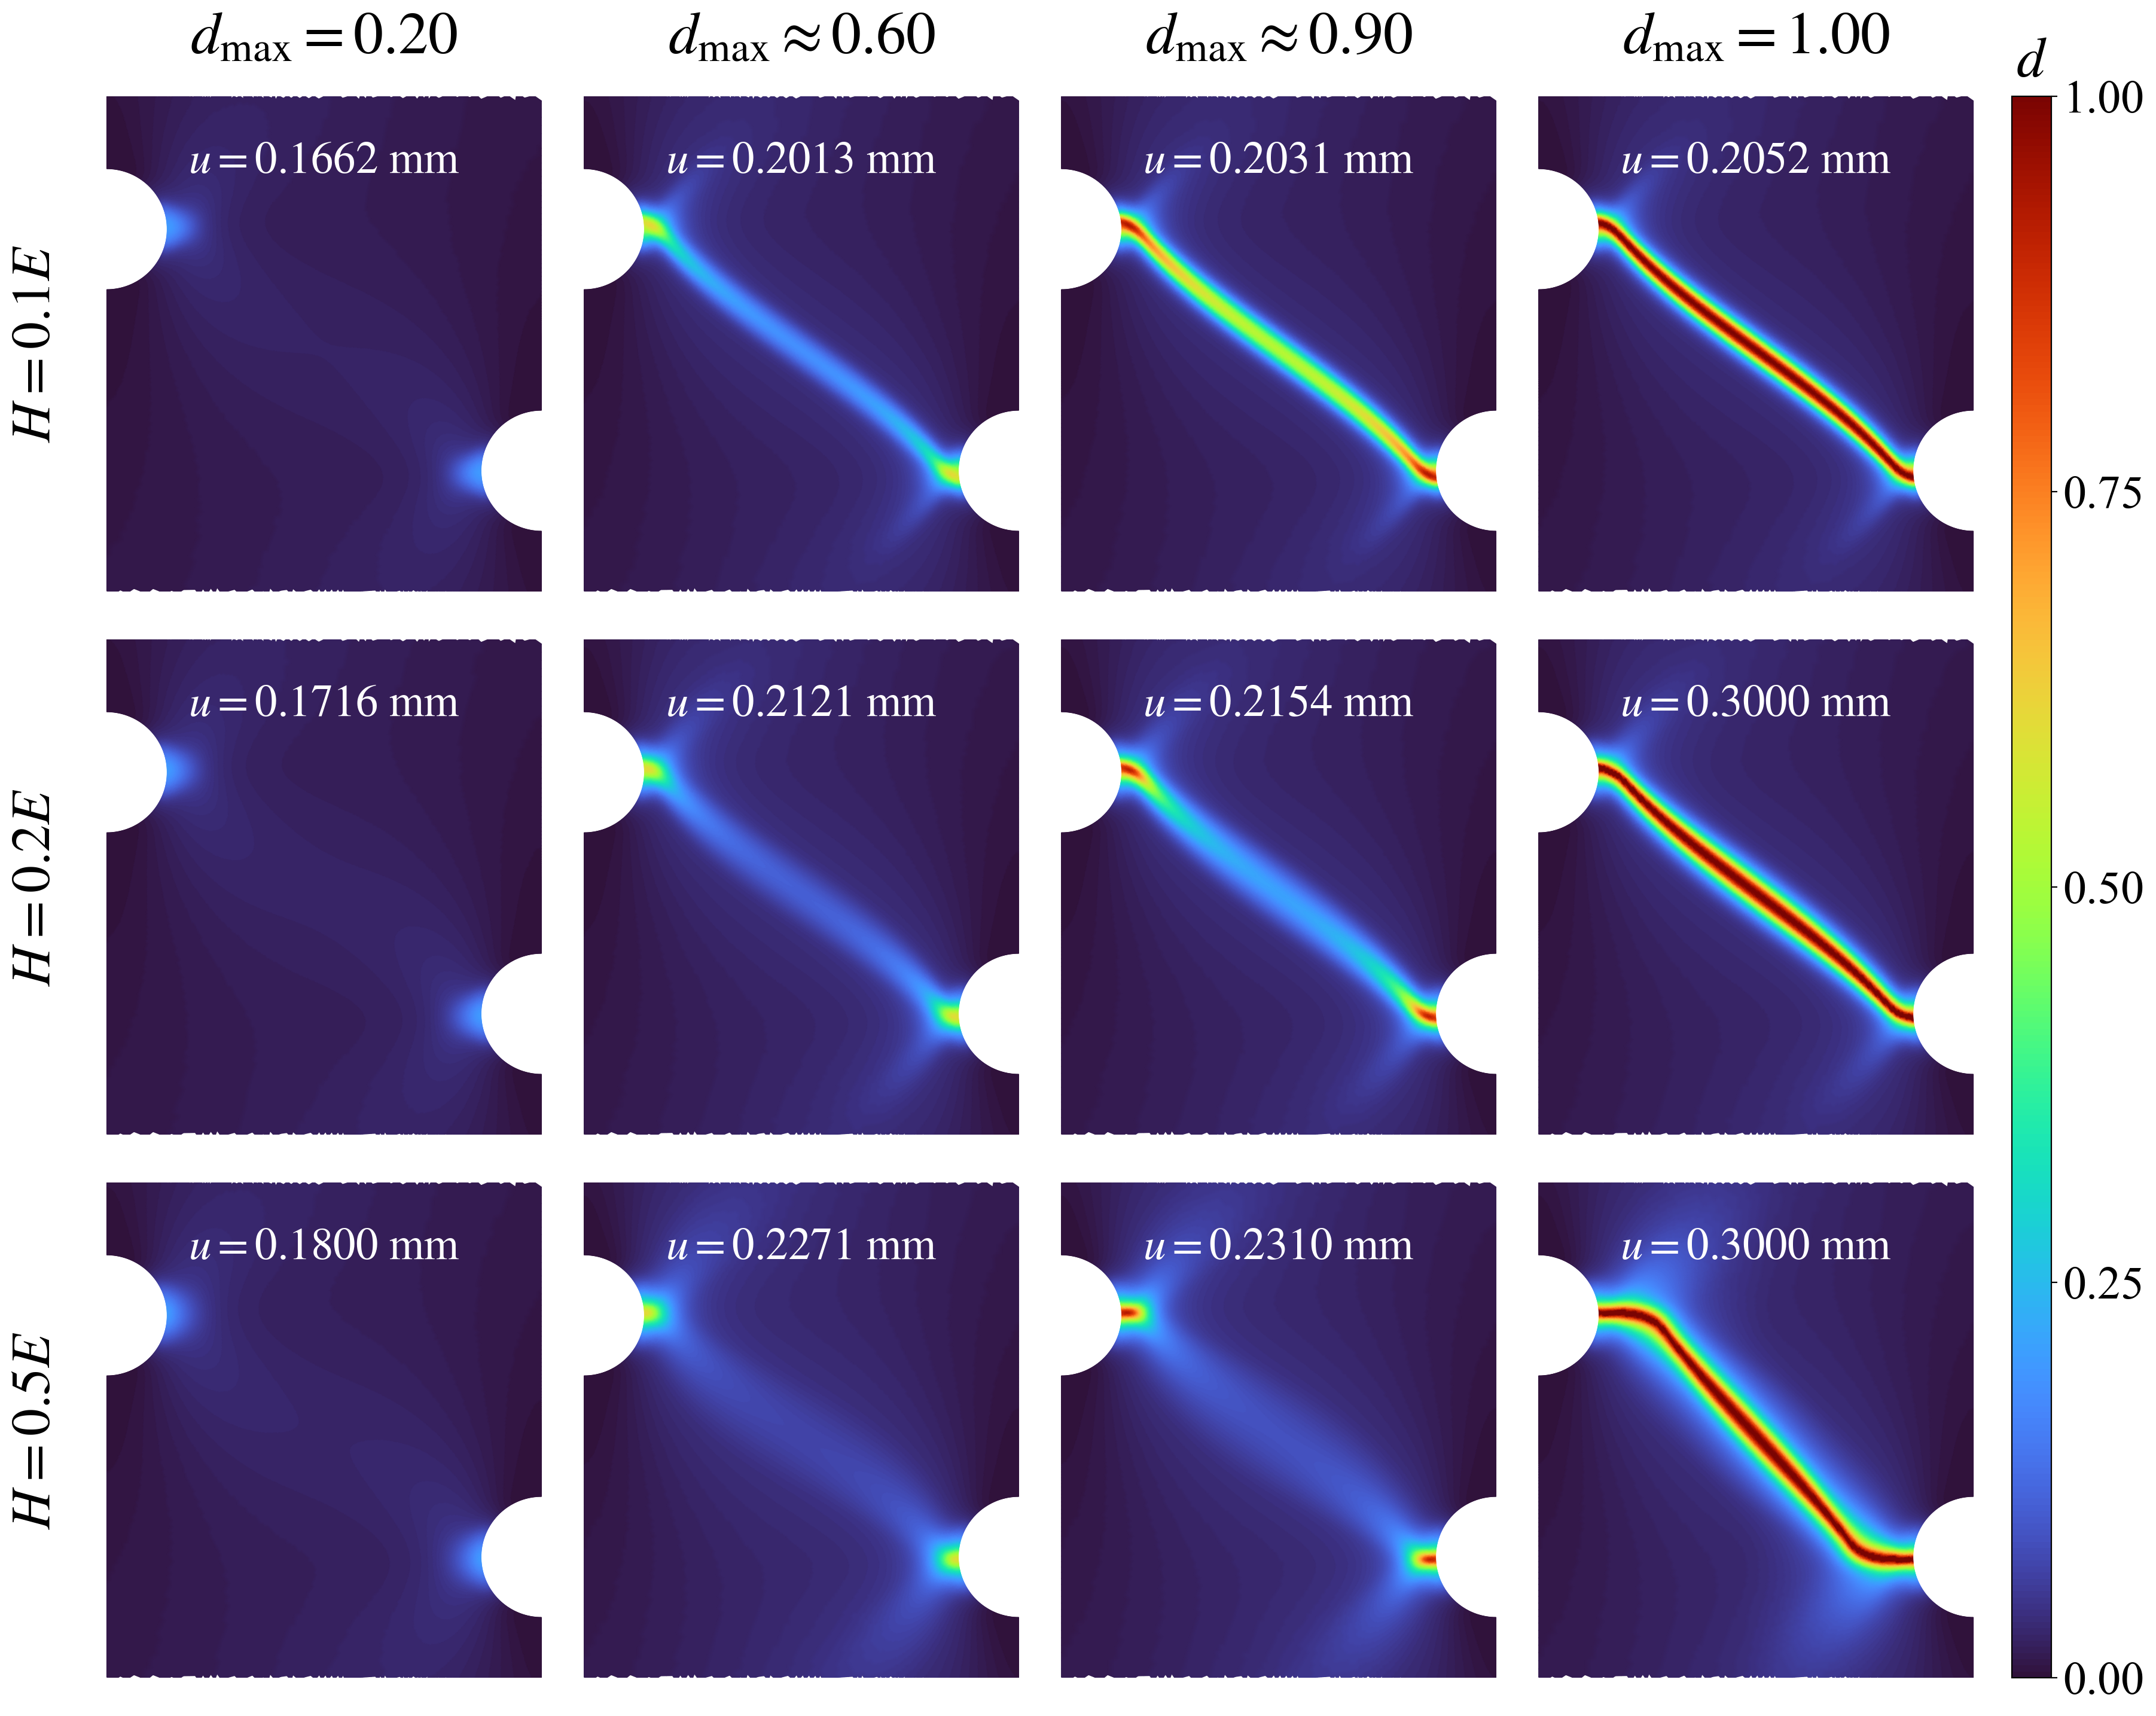

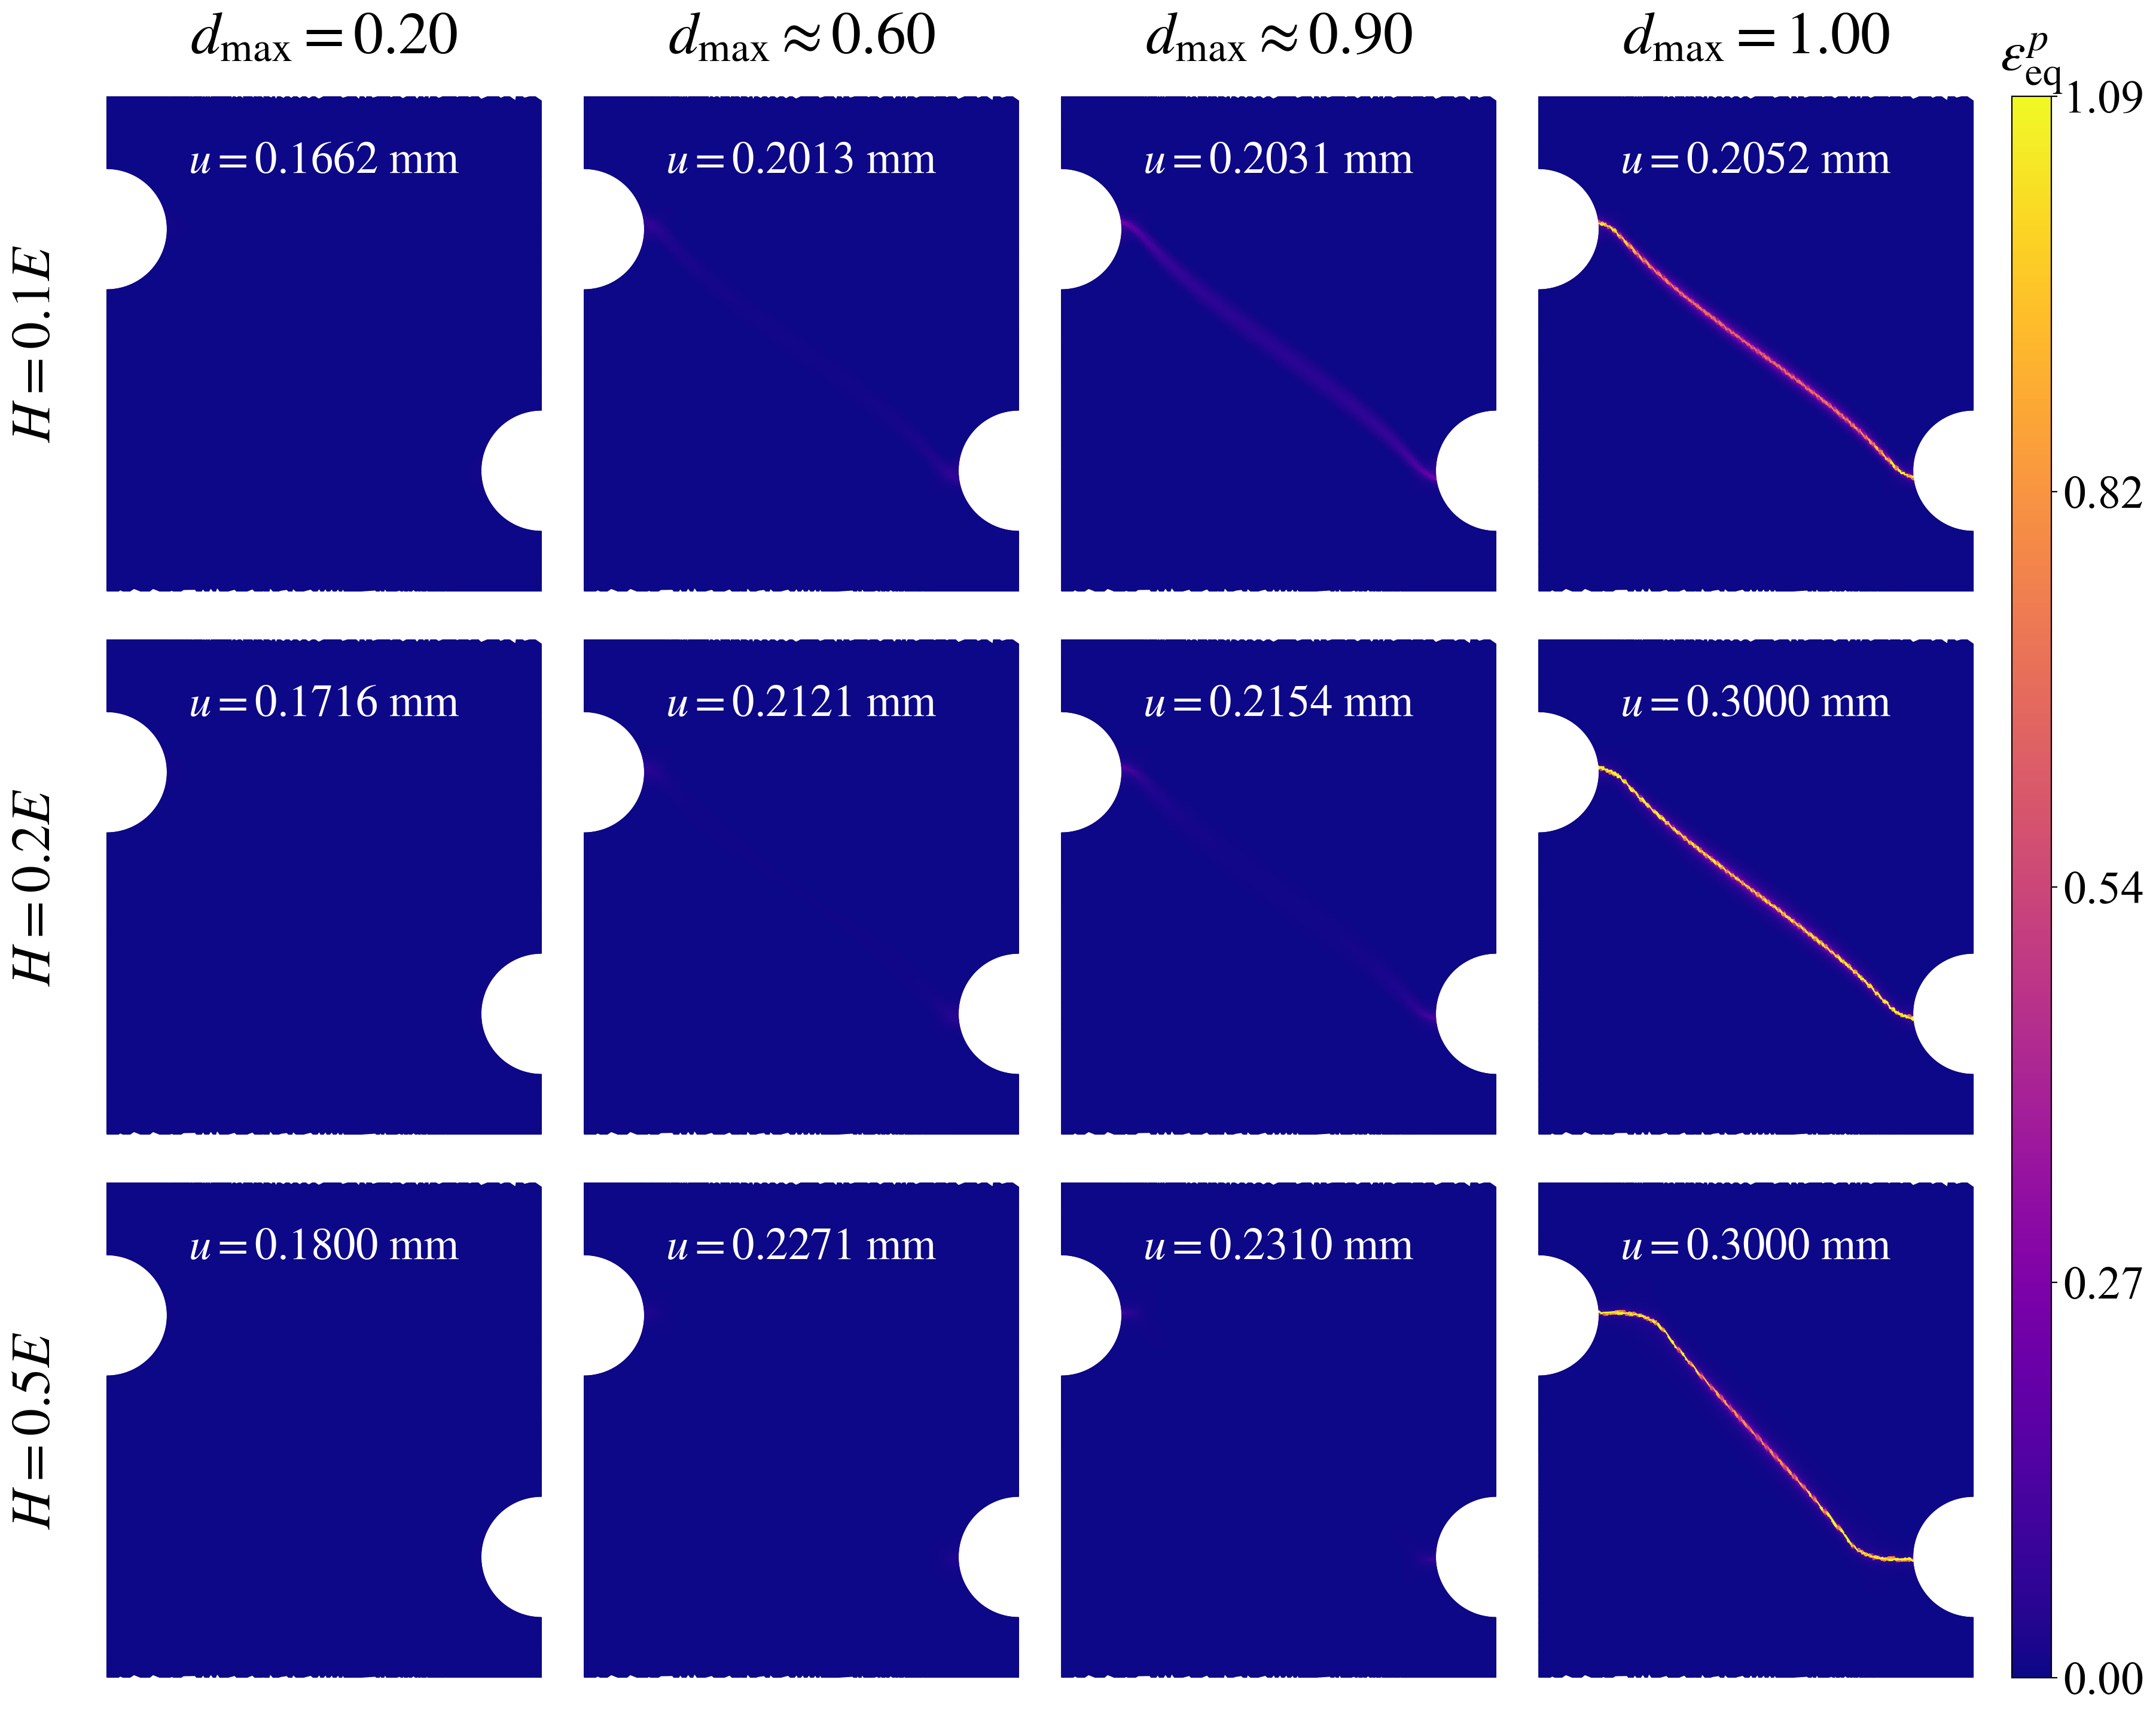

In [3]:
from pathlib import Path
import csv
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.gridspec import GridSpec
import meshio

mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size':        32,
    'figure.dpi':       200,
})

BASE      = Path('results_Fang2019_flat_grooved_scan')
BORDER_LW = 2.0
CROP_X    = (-0.5, 18.5)
CROP_Y    = (15.0, 35.5)

CASES = [
    dict(tag='H01E', label=r'$H = 0.1E$',
         files=['result_d020_step0554.vtu', 'result_d060_step0671.vtu',
                'result_d090_step0677.vtu', 'result_final.vtu'],
         csv_name='force_displacement_H01E.csv',
         steps=[554, 671, 677, None]),
    dict(tag='H02E', label=r'$H = 0.2E$',
         files=['result_d020_step0572.vtu', 'result_d060_step0707.vtu',
                'result_d090_step0718.vtu', 'result_final.vtu'],
         csv_name='force_displacement_H02E.csv',
         steps=[572, 707, 718, None]),
    dict(tag='H05E', label=r'$H = 0.5E$',
         files=['result_d020_step0600.vtu', 'result_d060_step0757.vtu',
                'result_d090_step0770.vtu', 'result_final.vtu'],
         csv_name='force_displacement_H05E.csv',
         steps=[600, 757, 770, None]),
]
N_ROWS, N_COLS = 3, 4

# ── load ──────────────────────────────────────────────────────────────────
print('Loading …')
for case in CASES:
    case_dir = BASE / case['tag']
    with open(case_dir / case['csv_name']) as f:
        rows = list(csv.DictReader(f))
    table    = {int(r['step']): r for r in rows}
    last_row = rows[-1]

    u_vals, d_vals = [], []
    for s in case['steps']:
        row = last_row if s is None else table[s]
        u_vals.append(float(row['u_mm']))
        d_vals.append(float(row['d_max']))
    case['u_vals'] = u_vals
    case['d_vals'] = d_vals

    snaps = []
    for fname in case['files']:
        mesh  = meshio.read(case_dir / fname)
        pts   = mesh.points[:, :2]
        cells = next(cb.data for cb in mesh.cells
                     if cb.type in ('triangle', 'triangle6'))
        if cells.shape[1] > 3:
            cells = cells[:, :3]
        cx = pts[cells, 0].mean(axis=1)
        cy = pts[cells, 1].mean(axis=1)
        mask = ((cx >= CROP_X[0]) & (cx <= CROP_X[1]) &
                (cy >= CROP_Y[0]) & (cy <= CROP_Y[1]))
        tri = mtri.Triangulation(pts[:, 0], pts[:, 1], triangles=cells[mask])
        snaps.append({'tri': tri,
                      'd':   mesh.point_data['d'].ravel(),
                      'ep':  mesh.point_data['epspeq'].ravel()})
    case['snaps'] = snaps
print('Done.')

# ── column headers: = if all rows same (2 dp), else ≈ ───────────────────
NOMINAL = [0.20, 0.60, 0.90, 1.00]   # nominal d level per column
col_hdrs = []
for c in range(N_COLS):
    vals_2dp = [round(case['d_vals'][c], 2) for case in CASES]
    sym = '=' if len(set(vals_2dp)) == 1 else r'\approx'
    col_hdrs.append(rf'$d_{{\max}} {sym} {NOMINAL[c]:.2f}$')
print('Column headers:', col_hdrs)

all_ep = np.concatenate([c['snaps'][-1]['ep'] for c in CASES])
EP_MAX = float(np.percentile(all_ep[all_ep > 1e-6], 99))

# ── figure builder ────────────────────────────────────────────────────────
def make_panel_figure(field_key, cmap_name, norm, cbar_label):
    cmap   = plt.get_cmap(cmap_name)
    crop_w = CROP_X[1] - CROP_X[0]
    crop_h = CROP_Y[1] - CROP_Y[0]
    CELL_W = 3.8
    CELL_H = CELL_W * crop_h / crop_w

    L_PAD, R_PAD = 1.5, 1.1
    T_PAD, B_PAD = 0.65, 0.25   # T_PAD reduced: header sits close to panels
    HS, WS = 0.08, 0.04

    fig_w = L_PAD + N_COLS * CELL_W * (1 + WS) + R_PAD
    fig_h = T_PAD + N_ROWS * CELL_H * (1 + HS) + B_PAD
    fig   = plt.figure(figsize=(fig_w, fig_h))

    lf = L_PAD / fig_w;  rf = 1 - R_PAD / fig_w
    bf = B_PAD / fig_h;  tf = 1 - T_PAD / fig_h
    gs = GridSpec(N_ROWS, N_COLS, figure=fig,
                  left=lf, right=rf, bottom=bf, top=tf,
                  hspace=HS, wspace=WS)
    ax_grid = [[fig.add_subplot(gs[r, c])
                for c in range(N_COLS)] for r in range(N_ROWS)]

    for r, case in enumerate(CASES):
        for c, snap in enumerate(case['snaps']):
            ax  = ax_grid[r][c]
            fld = snap[field_key]
            ax.tripcolor(snap['tri'], fld,
                         cmap=cmap, norm=norm,
                         shading='gouraud', rasterized=True)
            ax.set_xlim(CROP_X)
            ax.set_ylim(CROP_Y)
            ax.set_aspect('equal')
            ax.axis('off')
            for sp in ax.spines.values():
                sp.set_visible(True)
                sp.set_linewidth(BORDER_LW)
                sp.set_edgecolor('black')

            # u = xxx mm  inside panel, top area
            ax.text(0.50, 0.91,
                    rf'$u = {case["u_vals"][c]:.4f}$ mm',
                    transform=ax.transAxes,
                    ha='center', va='top',
                    fontsize=27, color='white', zorder=10)

    # ── column headers: d_max above row-0, large font, close to panels ────
    fig.canvas.draw()
    for c, hdr in enumerate(col_hdrs):
        pos = ax_grid[0][c].get_position()
        fig.text(0.5 * (pos.x0 + pos.x1),
                 pos.y1 + 0.018,          # very close to panel top
                 hdr,
                 ha='center', va='bottom',
                 fontsize=36)             # larger than panels

    # ── row labels ────────────────────────────────────────────────────────
    for r, case in enumerate(CASES):
        pos = ax_grid[r][0].get_position()
        fig.text(lf - 0.015, 0.5 * (pos.y0 + pos.y1),
                 case['label'],
                 ha='right', va='center', fontsize=33, rotation=90)

    # ── colorbar ──────────────────────────────────────────────────────────
    pos_top = ax_grid[0][-1].get_position()
    pos_bot = ax_grid[-1][-1].get_position()
    cax = fig.add_axes([pos_top.x1 + 0.012, pos_bot.y0,
                        0.018, pos_top.y1 - pos_bot.y0])
    cb  = fig.colorbar(
        mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
    cb.set_ticks(np.linspace(norm.vmin, norm.vmax, 5))
    cb.ax.yaxis.set_major_formatter(
        mpl.ticker.FuncFormatter(lambda x, _: f'{x:.2f}'))
    cb.ax.tick_params(labelsize=28)
    cb.ax.set_title(cbar_label, fontsize=34, pad=12)

    plt.show()

# ── Figure 1: damage d ────────────────────────────────────────────────────
make_panel_figure('d',  'turbo',  mpl.colors.Normalize(0.0, 1.0),    '$d$')

# ── Figure 2: equivalent plastic strain ──────────────────────────────────
make_panel_figure('ep', 'plasma', mpl.colors.Normalize(0.0, EP_MAX),
                  r'$\varepsilon^p_{\mathrm{eq}}$')

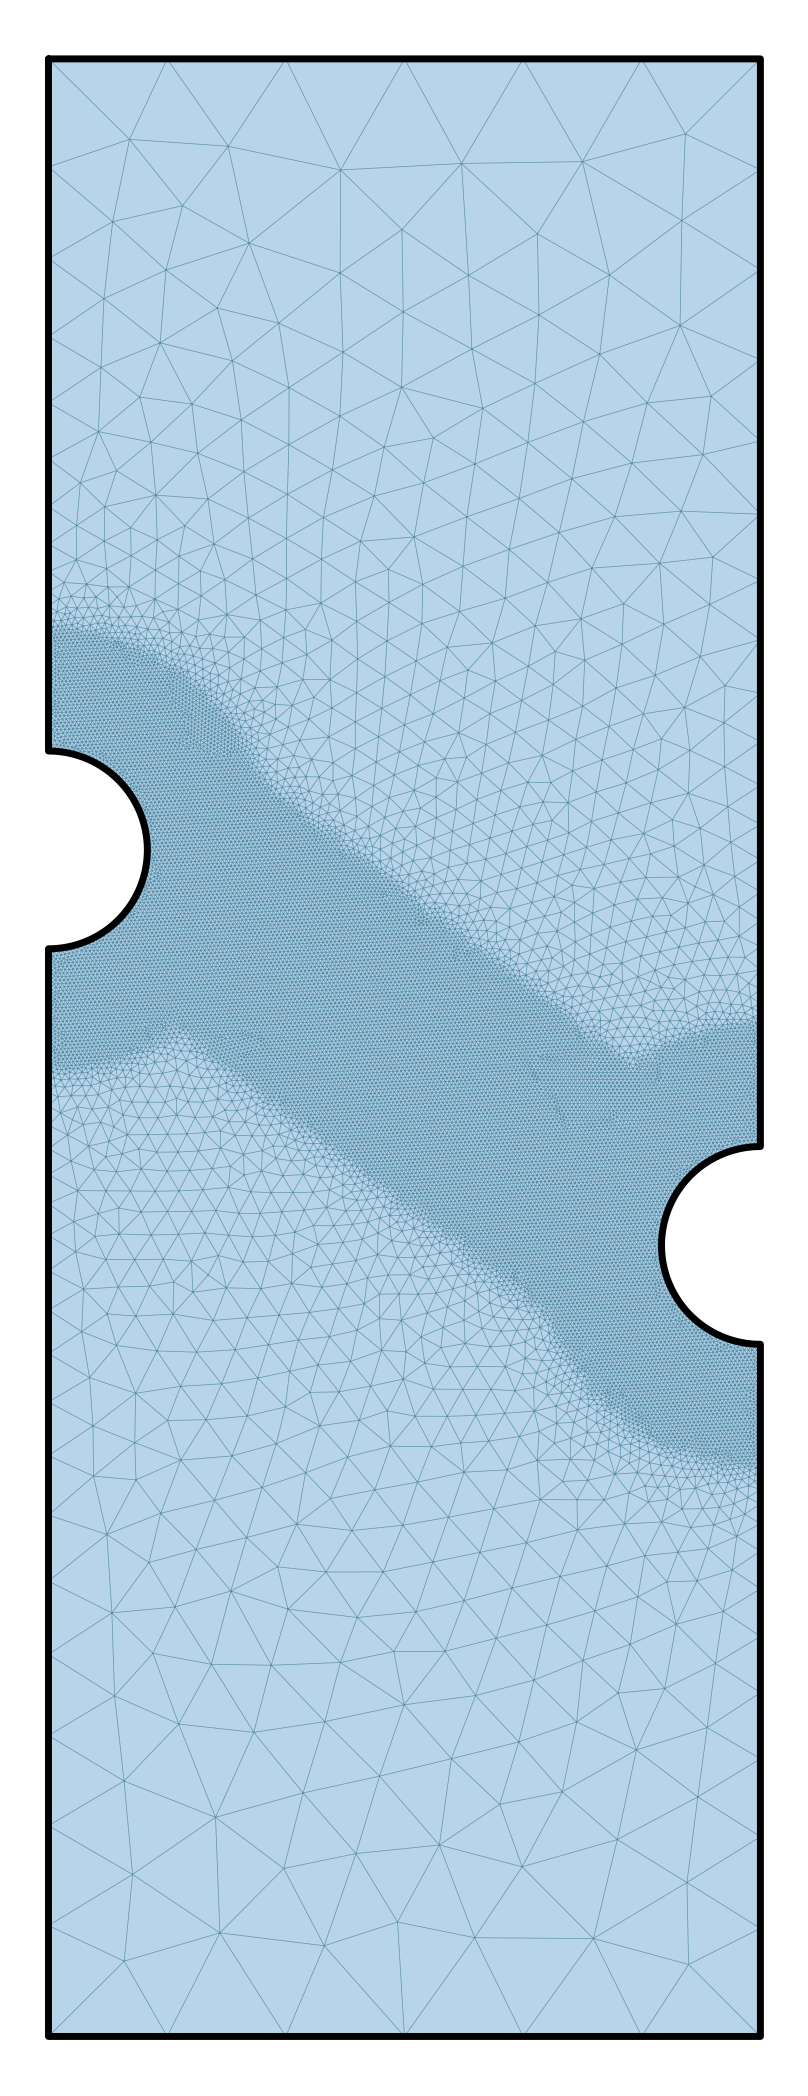

In [5]:
from pathlib import Path
from collections import defaultdict

import meshio
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.collections as mc
from scipy.spatial import cKDTree

msh_path = Path('results_Fang2019_flat_grooved_scan/H01E/mesh.msh')
mesh = meshio.read(msh_path)

coords = mesh.points[:, :2]
tris   = mesh.cells_dict['triangle']

# ── merge duplicate nodes (same as SENT version) ──────────────────────────
tree  = cKDTree(coords)
pairs = tree.query_pairs(r=1e-10)
parent = list(range(len(coords)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x

for a, b in pairs:
    ra, rb = find(a), find(b)
    if ra != rb: parent[ra] = rb

remap      = np.array([find(i) for i in range(len(coords))])
unique_ids, inv = np.unique(remap, return_inverse=True)
merged_coords   = coords[unique_ids]
merged_tris     = inv[tris].astype(int)

# ── boundary loops ─────────────────────────────────────────────────────────
edge_count = {}
for tri in merged_tris:
    for i in range(3):
        a, b = tri[i], tri[(i+1)%3]
        key  = (min(a,b), max(a,b))
        edge_count[key] = edge_count.get(key, 0) + 1

bdy_edges = {e for e, cnt in edge_count.items() if cnt == 1}
adj = defaultdict(list)
for a, b in bdy_edges:
    adj[a].append(b); adj[b].append(a)

visited, loops = set(), []
for start in adj:
    if start in visited: continue
    chain = [start]; visited.add(start); cur = start
    while True:
        nxt = [n for n in adj[cur] if n not in visited]
        if not nxt: break
        nxt = nxt[0]; visited.add(nxt); chain.append(nxt); cur = nxt
    if len(chain) > 1:
        loops.append(np.array([merged_coords[n] for n in chain]))

def poly_area(pts):
    x, y = pts[:,0], pts[:,1]
    return 0.5 * abs(np.dot(x, np.roll(y,-1)) - np.dot(y, np.roll(x,-1)))

outer_idx = int(np.argmax([poly_area(lp) for lp in loops]))

# ── plot ───────────────────────────────────────────────────────────────────
xmin, ymin = coords.min(axis=0)
xmax, ymax = coords.max(axis=0)
padx = 0.04*(xmax-xmin)
pady = 0.02*(ymax-ymin)

# aspect: W=18, H=50
fig, ax = plt.subplots(figsize=(4.2, 10.5))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# interior fill
ax.add_collection(mc.PolyCollection(
    coords[tris], facecolor='#B8D4E8', edgecolor='none', zorder=1))

# mesh lines
ax.triplot(coords[:,0], coords[:,1], tris,
           color='#5A8FAA', linewidth=0.25, zorder=2)

# boundary loops
for i, loop in enumerate(loops):
    closed = np.vstack([loop, loop[0]])
    lw = 2.5 if i == outer_idx else 1.2
    ax.plot(closed[:,0], closed[:,1],
            color='black', linewidth=lw,
            solid_capstyle='round', solid_joinstyle='round', zorder=3)

ax.set_xlim(xmin - padx, xmax + padx)
ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect('equal')
ax.axis('off')

plt.tight_layout(pad=0.3)
plt.show()

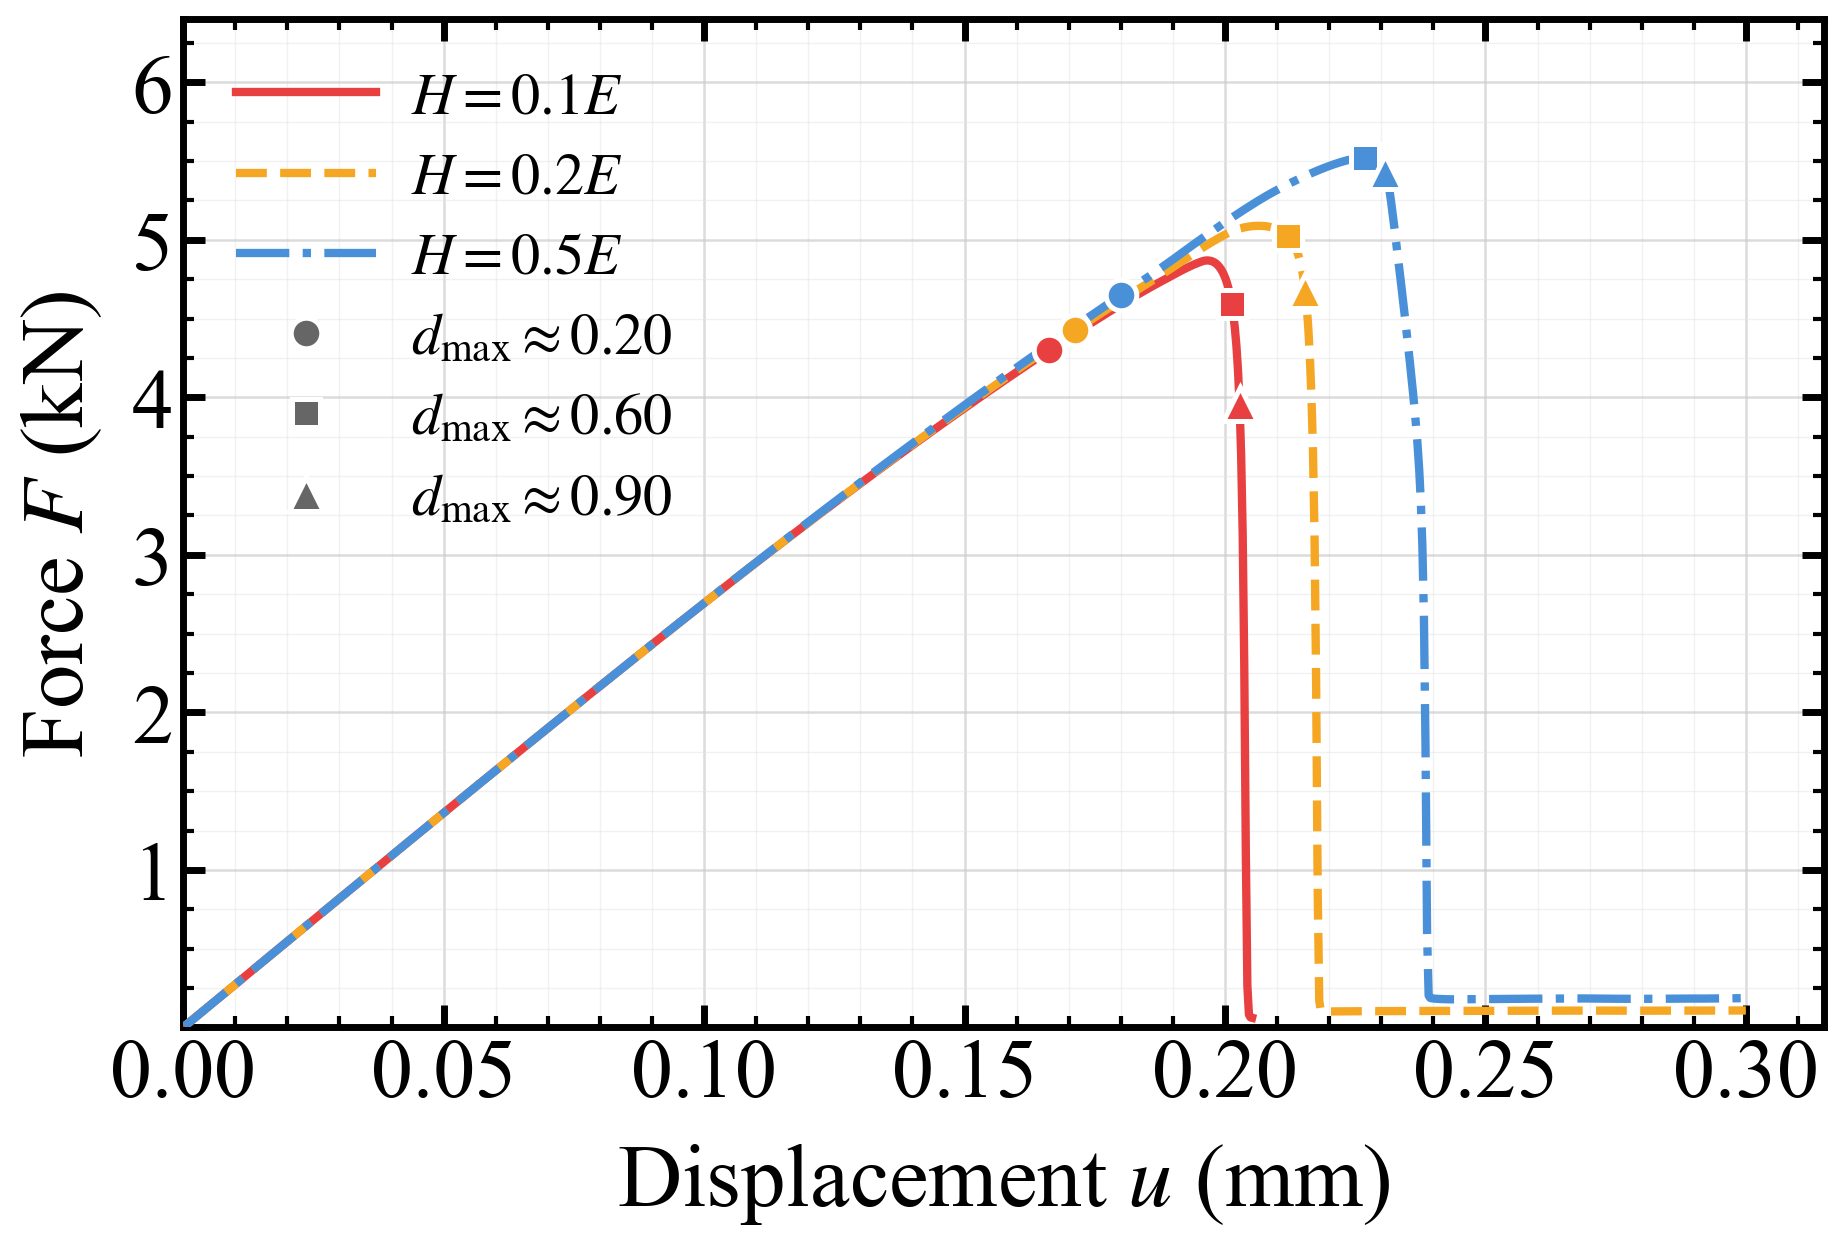

In [6]:
from pathlib import Path
import csv
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size':        28,
    'figure.dpi':       200,
})

BASE = Path('results_Fang2019_flat_grooved_scan')

CASES = [
    dict(tag='H01E', label=r'$H = 0.1E$', color='#E84040', ls='-'),
    dict(tag='H02E', label=r'$H = 0.2E$', color='#F5A623', ls='--'),
    dict(tag='H05E', label=r'$H = 0.5E$', color='#4A90D9', ls='-.'),
]

MILESTONES = [
    (0.20, r'$d_{\max} \approx 0.20$', 'o', 11),
    (0.60, r'$d_{\max} \approx 0.60$', 's', 10),
    (0.90, r'$d_{\max} \approx 0.90$', '^', 12),
]

# ── load ──────────────────────────────────────────────────────────────────
for case in CASES:
    with open(BASE / case['tag'] / f'force_displacement_{case["tag"]}.csv') as f:
        rows = list(csv.DictReader(f))
    case['u'] = np.array([float(r['u_mm']) for r in rows])
    case['F'] = np.array([float(r['F_kN']) for r in rows])
    case['d'] = np.array([float(r['d_max']) for r in rows])

# ── figure ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9.5, 6.5))

ax.set_axisbelow(True)
ax.grid(True, which='major', color='#CCCCCC', linewidth=0.9, alpha=0.7)
ax.grid(True, which='minor', color='#E5E5E5', linewidth=0.5, alpha=0.5)

# ── curves ────────────────────────────────────────────────────────────────
c_handles = []
for case in CASES:
    ln, = ax.plot(case['u'], case['F'],
                  color=case['color'], linestyle=case['ls'],
                  linewidth=3.0, zorder=4)
    c_handles.append(ln)

# ── milestone markers on each curve ───────────────────────────────────────
for case in CASES:
    for d_target, _, marker, ms in MILESTONES:
        idx = np.argmin(np.abs(case['d'] - d_target))
        ax.plot(case['u'][idx], case['F'][idx],
                marker=marker, markersize=ms,
                color=case['color'],
                markeredgecolor='white', markeredgewidth=1.8,
                linestyle='none', zorder=6)

# ── axes styling ──────────────────────────────────────────────────────────
ax.set_xlabel(r'Displacement $u$ (mm)', fontsize=32, labelpad=10)
ax.set_ylabel(r'Force $F$ (kN)',        fontsize=32, labelpad=10)

ax.tick_params(axis='both', which='major',
               labelsize=30, width=2.5, length=8, direction='in',
               top=True, right=True)
ax.tick_params(axis='both', which='minor',
               width=1.5, length=4, direction='in',
               top=True, right=True)
ax.xaxis.set_major_locator(ticker.MultipleLocator(0.05))
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.01))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.25))

# remove the 0 tick label on Y axis
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: '' if x == 0 else f'{x:g}'))

for spine in ax.spines.values():
    spine.set_linewidth(2.5)

ax.set_xlim(left=0)
ax.set_ylim(bottom=0, top=6.4)

# ── combined legend: curves first, then milestone markers ────────────────
curve_handles = [
    Line2D([0],[0], color=c['color'], linestyle=c['ls'],
           linewidth=3.0, label=c['label'])
    for c in CASES
]
marker_handles = [
    Line2D([0],[0], marker=mk, markersize=ms,
           color='#666666', markeredgecolor='white', markeredgewidth=1.8,
           linestyle='none', label=lbl)
    for _, lbl, mk, ms in MILESTONES
]

ax.legend(handles=curve_handles + marker_handles,
          fontsize=21, frameon=False,
          loc='upper left',
          handlelength=2.4, handletextpad=0.6,
          borderaxespad=0.5,
          labelspacing=0.45)

plt.tight_layout(pad=0.6)
plt.show()